# 阶段 5：业务落地

1. 预算约束下发给谁：增益模型 vs 响应模型 vs 随机
2. ROI 模拟：短信成本、毛利率等参数**全部是假设**，并做敏感性分析
3. 四类人群：用“不发也会买的概率”和“短信增量”两个维度分组，并用测试集的实际数据验证
4. 可解释的规则：在验证集上拟合一棵浅决策树，提炼投放规则，再到测试集上检验
5. 逻辑回归 T-learner 的系数解读

所有“实际效应”都用测试集的“实验组 − 对照组”计算；人群画像只说明相关，不说明因果。

## 5.1 预算约束下发给谁

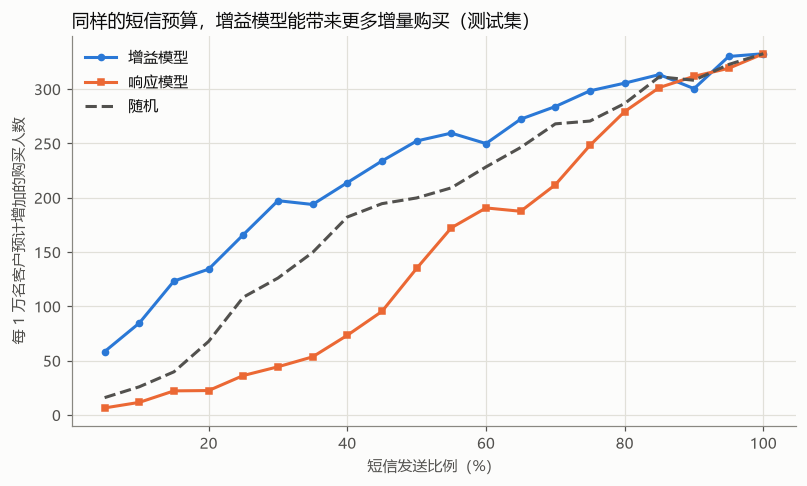

,增益模型,响应模型,随机
发送比例,,,
0.1,84.5,11.5,25.8
0.2,134.1,22.4,67.6
0.3,197.1,44.2,125.9
0.5,252.1,134.8,199.6
1.0,332.4,332.4,332.4


In [1]:
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor, export_text

from src.abtest import diff_in_means
from src.config import DATA_PROCESSED, RESULTS, SEED
from src.features import FEATURE_DESC
from src.meta_learners import TLearner, logistic
from src.plotting import GRID, INK_SECONDARY, MARKERS, SERIES, setup_matplotlib
from src.uplift_eval import uplift_curve

setup_matplotlib()
FEATURES = list(FEATURE_DESC)
data = pd.read_parquet(DATA_PROCESSED / "features.parquet")
split = pd.read_csv(DATA_PROCESSED / "split.csv", index_col=0)["split"].reindex(data.index)
test_pred = pd.read_parquet(DATA_PROCESSED / "test_predictions.parquet").set_index("client_id")
valid_pred = pd.read_parquet(DATA_PROCESSED / "valid_predictions.parquet").set_index("client_id")
FINAL = json.loads((RESULTS / "stage3_summary.json").read_text(encoding="utf-8"))["最终模型（按验证集 Qini 系数）"]
RESPONSE = "响应模型（LightGBM，对照）"
test = data.loc[test_pred.index].join(test_pred[[FINAL, RESPONSE, "最终模型·不发短信时的购买概率"]])
y, t = test["target"].to_numpy(), test["treatment_flg"].to_numpy()
N = len(test)

rng = np.random.default_rng(SEED)
strategies = {"增益模型": test[FINAL].to_numpy(), "响应模型": test[RESPONSE].to_numpy(), "随机": rng.random(N)}
curves = {name: uplift_curve(y, s, t) for name, s in strategies.items()}
ks = np.round(np.arange(0.05, 1.0001, 0.05), 2)
budget = pd.DataFrame({name: [float(np.interp(int(N * k), *curves[name])) / N * 10_000 for k in ks]
                       for name in strategies}, index=ks)
budget.index.name = "发送比例"
budget.to_csv(RESULTS / "stage5_budget_gain.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for i, name in enumerate(strategies):
    ax.plot(ks * 100, budget[name], color=[SERIES[0], SERIES[1], INK_SECONDARY][i],
            linestyle="--" if name == "随机" else "-", marker=None if name == "随机" else MARKERS[i], markersize=4,
            linewidth=2, label=name)
ax.set_xlabel("短信发送比例（%）")
ax.set_ylabel("每 1 万名客户预计增加的购买人数")
ax.set_title("同样的短信预算，增益模型能带来更多增量购买（测试集）", loc="left")
ax.legend(frameon=False)
fig.savefig(RESULTS / "stage5_budget_gain.png")
plt.show()
budget.loc[[0.1, 0.2, 0.3, 0.5, 1.0]].round(1)

## 5.2 ROI 模拟（参数全部是假设）

数据没有说明币种，下面的金额单位和数据里的交易金额一致。
- **【假设】短信成本**：每条 2 个单位；
- **【假设】每次增量购买带来的毛利** = 客单价中位数 × 毛利率 25%。注意：“购买”只是一个 0/1 标签，这里假设每次增量购买的金额等于客单价中位数；
- 利润 = 增量购买人数 × 单次毛利 − 发送条数 × 短信成本。

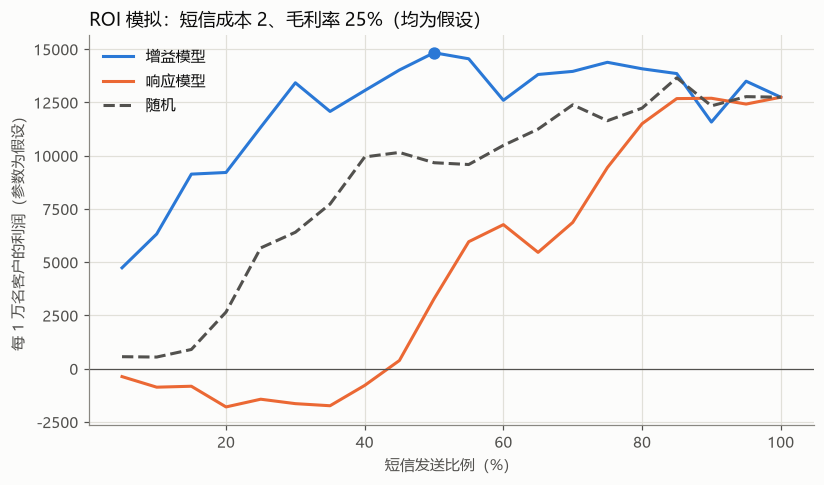

{'客单价中位数': 393.9998461538462,
 '【假设】毛利率': 0.25,
 '【假设】短信成本': 2.0,
 '单次增量购买毛利': 98.49996153846155,
 '利润最高的发送比例': {'增益模型': 0.5, '响应模型': 1.0, '随机': 0.85},
 '每 1 万名客户的最高利润': {'增益模型': 14828.418951302676,
  '响应模型': 12740.67631890364,
  '随机': 13650.617607797514},
 '全部发送时的利润（每 1 万人）': {'增益模型': 12740.67631890364,
  '响应模型': 12740.67631890364,
  '随机': 12740.67631890364}}

In [2]:
SMS_COST = 2.0          # 【假设】
MARGIN_RATE = 0.25      # 【假设】
basket = float(data["avg_sum"].median())
profit_per_purchase = basket * MARGIN_RATE


def profit_curve(gain_per_10k, ks, sms_cost, profit_per_purchase):
    return gain_per_10k * profit_per_purchase - ks * 10_000 * sms_cost


roi = pd.DataFrame({name: profit_curve(budget[name].to_numpy(), ks, SMS_COST, profit_per_purchase) for name in strategies},
                   index=ks)
roi.index.name = "发送比例"
best_k = {name: float(roi[name].idxmax()) for name in strategies}
best_profit = {name: float(roi[name].max()) for name in strategies}
roi_summary = {"客单价中位数": basket, "【假设】毛利率": MARGIN_RATE, "【假设】短信成本": SMS_COST,
               "单次增量购买毛利": profit_per_purchase,
               "利润最高的发送比例": best_k, "每 1 万名客户的最高利润": best_profit,
               "全部发送时的利润（每 1 万人）": {name: float(roi[name].iloc[-1]) for name in strategies}}
roi.to_csv(RESULTS / "stage5_roi_curve.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for i, name in enumerate(strategies):
    ax.plot(ks * 100, roi[name], color=[SERIES[0], SERIES[1], INK_SECONDARY][i],
            linestyle="--" if name == "随机" else "-", linewidth=2, label=name)
ax.axhline(0, color=INK_SECONDARY, linewidth=0.8)
ax.scatter([best_k["增益模型"] * 100], [best_profit["增益模型"]], color=SERIES[0], s=50, zorder=3)
ax.set_xlabel("短信发送比例（%）")
ax.set_ylabel("每 1 万名客户的利润（参数为假设）")
ax.set_title(f"ROI 模拟：短信成本 {SMS_COST:g}、毛利率 {MARGIN_RATE:.0%}（均为假设）", loc="left")
ax.legend(frameon=False)
fig.savefig(RESULTS / "stage5_roi_curve.png")
plt.show()
roi_summary

### 敏感性分析：换一组假设，结论还成立吗？

短信成本取 1 / 2 / 5，毛利率取 10% / 25% / 40%，看增益模型的最优发送比例，以及它比“全部发送”多赚多少。

In [3]:
sens_rows = []
for cost in [1.0, 2.0, 5.0]:
    for rate in [0.10, 0.25, 0.40]:
        ppp = basket * rate
        p_up = profit_curve(budget["增益模型"].to_numpy(), ks, cost, ppp)
        p_resp = profit_curve(budget["响应模型"].to_numpy(), ks, cost, ppp)
        sens_rows.append({"【假设】短信成本": cost, "【假设】毛利率": rate,
                          "增益模型最优发送比例": float(ks[p_up.argmax()]), "增益模型最高利润": float(p_up.max()),
                          "响应模型最高利润": float(p_resp.max()), "全部发送的利润": float(p_up[-1]),
                          "增益模型比全部发送多赚": float(p_up.max() - p_up[-1])})
sensitivity = pd.DataFrame(sens_rows)
sensitivity.to_csv(RESULTS / "stage5_roi_sensitivity.csv", index=False, encoding="utf-8-sig")
sensitivity.round(1)

,【假设】短信成本,【假设】毛利率,增益模型最优发送比例,增益模型最高利润,响应模型最高利润,全部发送的利润,增益模型比全部发送多赚
0,1.0,0.1,0.5,4931.4,3370.2,3096.3,1835.1
1,1.0,0.2,1.0,22991.8,22740.7,22740.7,251.1
2,1.0,0.4,1.0,42486.9,42385.1,42385.1,101.8
3,2.0,0.1,0.2,1852.0,-749.8,-6903.7,8755.7
4,2.0,0.2,0.5,14828.4,12740.7,12740.7,2087.7
5,2.0,0.4,1.0,32986.9,32385.1,32385.1,601.8
6,5.0,0.1,0.0,-207.0,-2249.8,-36903.7,36696.7
7,5.0,0.2,0.2,4629.9,-1874.4,-17259.3,21889.3
8,5.0,0.4,0.3,16067.5,4980.8,2385.1,13682.4


## 5.3 四类人群

用最终模型（T-learner）的两个输出，按测试集的中位数把客户分成四类：
- **不发也会买的概率**（对照组模型的预测）：高 / 低；
- **预测的短信增量**：高 / 低。

| | 增量高 | 增量低 |
|---|---|---|
| 不发也会买的概率低 | 可说服的人（Persuadables）：最该发 | 没救型（Lost Causes）：发了也不买 |
| 不发也会买的概率高 | 高基础、高增量 | 铁定买（Sure Things）：不发也会买 |

每一类都用测试集的“实验组 − 对照组”验证实际增益。

In [4]:
p0 = test["最终模型·不发短信时的购买概率"]
upl = test[FINAL]
high_p0 = p0 >= p0.median()
high_up = upl >= upl.median()
labels = np.select([~high_p0 & high_up, high_p0 & ~high_up, ~high_p0 & ~high_up, high_p0 & high_up],
                   ["可说服的人：不发概率低、增量高", "铁定买：不发概率高、增量低", "没救型：不发概率低、增量低",
                    "高基础、高增量"], default="其他")
test["人群"] = labels
rows = []
for g, d in test.groupby("人群"):
    r = diff_in_means(d["target"], d["treatment_flg"])
    rows.append({"人群": g, "人数占比": len(d) / N, "实际对照组购买率": r["对照组均值"], "实际增益": r["ATE"],
                 "增益标准误": r["标准误"], "交易次数中位数": d["n_trans"].median(), "客单价中位数": d["avg_sum"].median(),
                 "年龄中位数": d["age"].median(), "办卡天数中位数": d["days_since_issue"].median(),
                 "最近一次交易距今中位数": d["recency_days"].median()})
quadrants = pd.DataFrame(rows).set_index("人群")
quadrants.to_csv(RESULTS / "stage5_quadrants.csv", encoding="utf-8-sig")
quadrants.round(3)

,人数占比,实际对照组购买率,实际增益,增益标准误,交易次数中位数,客单价中位数,年龄中位数,办卡天数中位数,最近一次交易距今中位数
人群,,,,,,,,,
可说服的人：不发概率低、增量高,0.312,0.410,0.060,0.009,8.0,403.789,51.0,379.0,9.0
没救型：不发概率低、增量低,0.188,0.404,0.002,0.011,8.0,505.517,35.0,553.0,10.0
铁定买：不发概率高、增量低,0.312,0.834,0.016,0.007,32.0,367.465,42.0,572.0,2.0
高基础、高增量,0.188,0.748,0.035,0.010,21.0,340.579,56.0,424.0,3.0


## 5.4 可解释的投放规则：用一棵浅决策树概括模型

- 在**验证集**上，用客户特征去拟合最终模型的预测增益（最多 3 层，每个叶子至少 2,000 人），得到几条容易讲清楚的规则；
- 再到**测试集**上，按同样的规则把客户分组，用“实验组 − 对照组”检验每组的实际增益。

这样规则的提炼和检验用的是不同的数据，避免“自己出题自己答”。

In [5]:
valid = data.loc[valid_pred.index]
tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=2000, random_state=SEED)
Xv = valid[FEATURES].fillna(valid[FEATURES].median())
tree.fit(Xv, valid_pred[FINAL])
rules_text = export_text(tree, feature_names=FEATURES, decimals=3)
print(rules_text)

Xt = test[FEATURES].fillna(valid[FEATURES].median())
test["规则叶子"] = tree.apply(Xt)
leaf_rows = []
for leaf, d in test.groupby("规则叶子"):
    r = diff_in_means(d["target"], d["treatment_flg"])
    leaf_rows.append({"叶子编号": int(leaf), "验证集上的预测增益": float(tree.tree_.value[leaf][0][0]),
                      "测试集人数": len(d), "测试集实际增益": r["ATE"], "增益标准误": r["标准误"],
                      "测试集对照组购买率": r["对照组均值"]})
leaves = pd.DataFrame(leaf_rows).sort_values("验证集上的预测增益", ascending=False)
spearman = float(leaves["验证集上的预测增益"].corr(leaves["测试集实际增益"], method="spearman"))
leaves.to_csv(RESULTS / "stage5_tree_leaves.csv", index=False, encoding="utf-8-sig")
(RESULTS / "stage5_tree_rules.txt").write_text(rules_text, encoding="utf-8")
print("叶子上“验证集预测增益”与“测试集实际增益”的 Spearman 相关：", round(spearman, 3))
leaves.round(4)

|--- express_points_spent <= -26.500
|   |--- n_active_days <= 18.500
|   |   |--- value: [0.095]
|   |--- n_active_days >  18.500
|   |   |--- value: [0.042]
|--- express_points_spent >  -26.500
|   |--- days_since_issue <= 292.500
|   |   |--- age <= 44.500
|   |   |   |--- value: [0.030]
|   |   |--- age >  44.500
|   |   |   |--- value: [0.058]
|   |--- days_since_issue >  292.500
|   |   |--- age <= 44.500
|   |   |   |--- value: [0.007]
|   |   |--- age >  44.500
|   |   |   |--- value: [0.028]

叶子上“验证集预测增益”与“测试集实际增益”的 Spearman 相关： 0.714


,叶子编号,验证集上的预测增益,测试集人数,测试集实际增益,增益标准误,测试集对照组购买率
0,2,0.0950,3592,0.0775,0.0166,0.4598
3,7,0.0575,4435,0.0315,0.0145,0.6099
1,3,0.0415,2181,0.0411,0.0155,0.8242
2,6,0.0305,4836,0.0173,0.0142,0.5709
5,10,0.0280,13058,0.0278,0.0084,0.6262
4,9,0.0066,11906,0.0311,0.0089,0.5916


## 5.5 逻辑回归 T-learner 的系数解读

T-learner（逻辑回归）由两个逻辑回归组成：实验组模型和对照组模型。特征都标准化过，所以可以比较系数大小。
**两组系数之差**表示：这个特征每增加一个标准差，在“收到短信”时和“没收到短信”时对购买对数几率的影响差多少。差为正，说明这个特征越高的人，短信的作用越大（只是相关，不是因果）。

In [6]:
tr = data[split == "train"]
model = TLearner(logistic()).fit(tr[FEATURES].to_numpy(float), tr["target"].to_numpy(), tr["treatment_flg"].to_numpy())
coef_t = model.model_t_[-1].coef_[0]
coef_c = model.model_c_[-1].coef_[0]
coefs = pd.DataFrame({"实验组模型系数": coef_t, "对照组模型系数": coef_c, "系数差（实验组 − 对照组）": coef_t - coef_c,
                      "含义": [FEATURE_DESC[c][1] for c in FEATURES]}, index=FEATURES)
coefs = coefs.reindex(coefs["系数差（实验组 − 对照组）"].abs().sort_values(ascending=False).index)
coefs.to_csv(RESULTS / "stage5_tlearner_coefficients.csv", encoding="utf-8-sig")
coefs.head(12).round(3)

,实验组模型系数,对照组模型系数,系数差（实验组 − 对照组）,含义
avg_sum,-0.208,-0.038,-0.170,平均每笔交易金额（客单价）
median_sum,0.088,-0.051,0.139,交易金额中位数
regular_points_received,0.123,0.001,0.121,获得的普通积分合计
n_trans,-1.254,-1.136,-0.117,截止日前的交易次数
express_points_spent,-0.080,0.013,-0.093,花掉的活动积分合计（负数）
total_sum,-0.047,0.043,-0.090,消费总额
mean_hour,-0.038,0.045,-0.084,平均交易小时
days_since_issue,-0.165,-0.084,-0.081,办卡距截止日的天数
n_active_days,1.439,1.366,0.073,有交易的天数
share_trans_points_spent,0.007,-0.064,0.070,使用积分的交易占比（促销敏感度）


## 5.6 保存结果

In [7]:
(RESULTS / "stage5_summary.json").write_text(json.dumps({
    "预算与增量（每 1 万名客户预计增加的购买人数）": json.loads(budget.loc[[0.1, 0.2, 0.3, 0.5, 1.0]].to_json(orient="index", force_ascii=False)),
    "ROI（参数为假设）": roi_summary,
    "四类人群": json.loads(quadrants.to_json(orient="index", force_ascii=False)),
    "决策树规则：叶子上预测与实际增益的 Spearman 相关": spearman,
}, ensure_ascii=False, indent=2), encoding="utf-8")
print("已保存：stage5_budget_gain.csv/png、stage5_roi_curve.csv/png、stage5_roi_sensitivity.csv、stage5_quadrants.csv、"
      "stage5_tree_rules.txt、stage5_tree_leaves.csv、stage5_tlearner_coefficients.csv、stage5_summary.json")

已保存：stage5_budget_gain.csv/png、stage5_roi_curve.csv/png、stage5_roi_sensitivity.csv、stage5_quadrants.csv、stage5_tree_rules.txt、stage5_tree_leaves.csv、stage5_tlearner_coefficients.csv、stage5_summary.json
